# **Práctica 1**

In [1]:
from qiskit import QuantumRegister, QuantumCircuit, generate_preset_pass_manager
from qiskit import transpile
from qiskit_aer import Aer
# from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_aer import AerSimulator
from qiskit.circuit.library import *

import numpy as np
# Importing standard Qiskit libraries
from qiskit.visualization import *

from qiskit.quantum_info import Statevector, Pauli, Operator

from tabulate import tabulate

from functools import reduce
import matplotlib.pyplot as plt



## **Bloque 1: Funcionamiento de las puertas cuánticas de 1 qubit**

In [2]:
# Creo una lista con las puertas que voy a utilizar
gates = [XGate(), YGate(), ZGate(), HGate(), SGate(), TGate()]

sv0, sv1 = [], []

In [3]:
q0 = QuantumCircuit(1)

q1 = QuantumCircuit(1)
q1.x(0) # Le aplico una puerta X para cambiar del estado |0> inicial al |1>

In [4]:
state0 = Statevector(q0)
state1 = Statevector(q1)

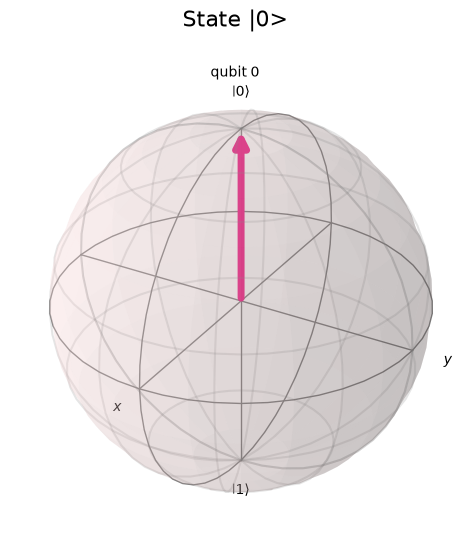

In [5]:
fig = plot_bloch_multivector(state0.data, title = 'State |0>')
fig.savefig(f'./figures/b1_state0.png', dpi = 300, bbox_inches = 'tight')
fig

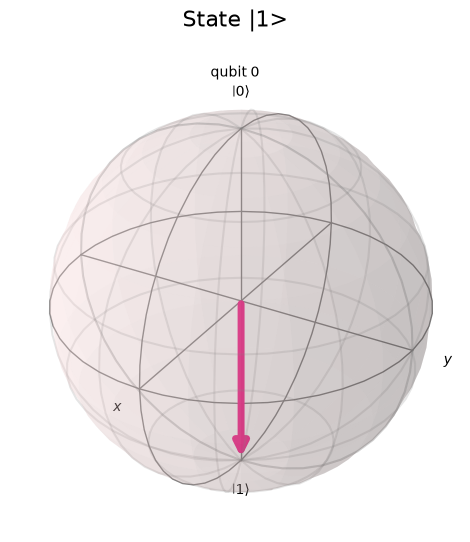

In [6]:
fig = plot_bloch_multivector(state1.data, title = 'State |1>')
fig.savefig(f'./figures/b1_state1.png', dpi = 300, bbox_inches = 'tight')
fig

In [7]:
# Aplico las puertas al estado 0
for g in gates:
    aux0 = q0.copy()
    aux0.append(g, aux0.qubits)
    sv0.append(Statevector(aux0))


    aux1 = q1.copy()

    aux1.append(g, aux1.qubits)
    sv1.append(Statevector(aux1))

In [8]:
gates_names = ['X', 'Y', 'Z', 'H', 'S', 'T']
headers = ['Puertas', 'Estado |0>', 'Estado |1>']
data = [[gates_names[i], sv0[i].data, sv1[i].data] for i in range(len(gates_names))]

table = tabulate(data, headers = headers)

print(table)

Puertas    Estado |0>                       Estado |1>
---------  -------------------------------  -----------------------------------------------
X          [0.+0.j 1.+0.j]                  [1.+0.j 0.+0.j]
Y          [0.+0.j 0.+1.j]                  [0.-1.j 0.+0.j]
Z          [1.+0.j 0.+0.j]                  [ 0.+0.j -1.+0.j]
H          [0.70710678+0.j 0.70710678+0.j]  [ 0.70710678+0.j -0.70710678+0.j]
S          [1.+0.j 0.+0.j]                  [0.+0.j 0.+1.j]
T          [1.+0.j 0.+0.j]                  [0.        +0.j         0.70710678+0.70710678j]


In [9]:
# Obtenemos el vector real de la esfera de bloch
def bloch_vector(sv):
    return [sv.expectation_value(Pauli(p)).real for p in 'XYZ']

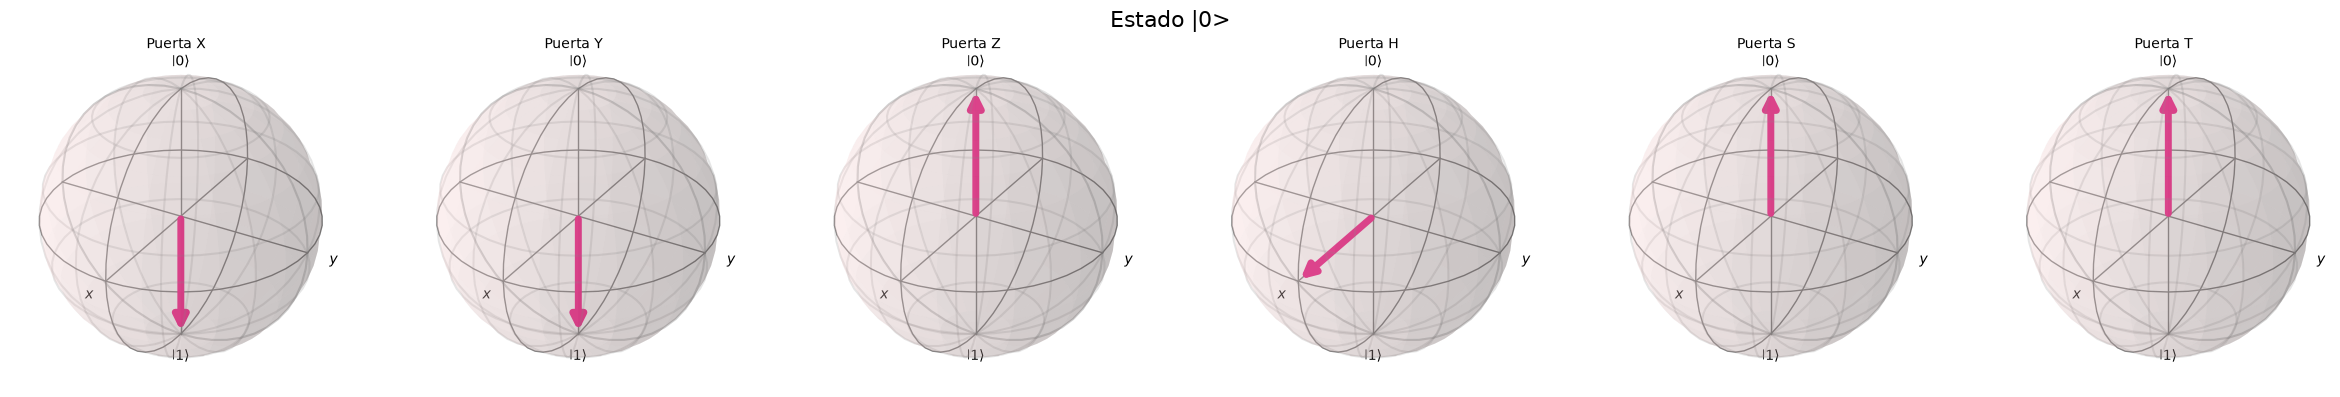

In [10]:
n = len(sv0)
ncols = n
nrows = 1

fig = plt.figure(figsize=(4 * ncols, 4 * nrows))
for i, sv in enumerate(sv0):
    ax = fig.add_subplot(nrows, ncols, i + 1, projection='3d')
    plot_bloch_vector(bloch_vector(sv), title=f"Puerta {gates_names[i]}", ax=ax)

fig.suptitle("Estado |0>", fontsize=16)
fig.savefig(f'./figures/b1_bloch_spheres_state0.png', dpi = 300, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

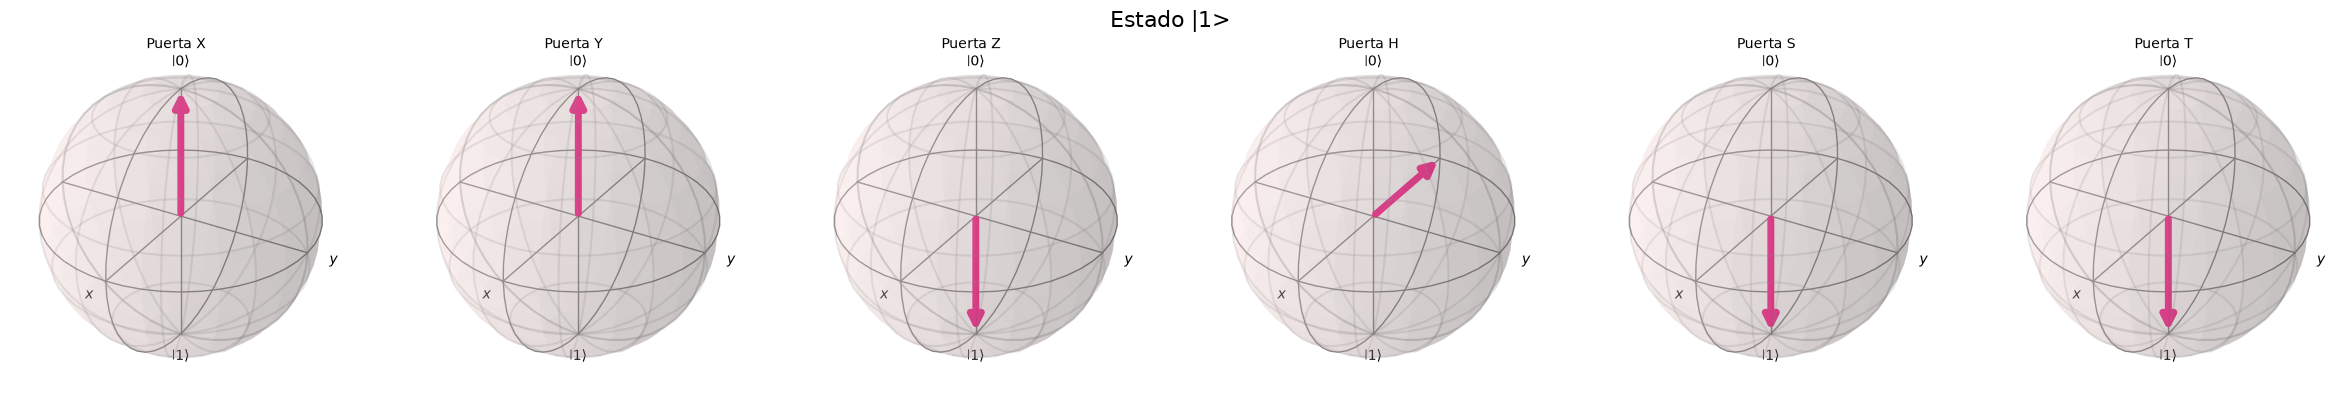

In [11]:
n = len(sv1)
ncols = n
nrows = 1

fig = plt.figure(figsize=(4 * ncols, 4 * nrows))
for i, sv in enumerate(sv1):
    ax = fig.add_subplot(nrows, ncols, i + 1, projection='3d')
    plot_bloch_vector(bloch_vector(sv), title=f"Puerta {gates_names[i]}", ax=ax)

fig.suptitle("Estado |1>", fontsize=16)
fig.savefig(f'./figures/b1_bloch_spheres_state1.png', dpi = 300, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

## **Bloque 2: Puertas de 2 qubits y equivalencias**

### Ejercicio 1
"Realizada en la memoria"

### Ejercicio 2

Supongamos que tenemos un estado $\ket{q_1q_2} = \ket{a}\ket{b}$ (en la nomenclatura de Qiskit sería $\ket{q_2q_1} = \ket{a}\ket{b}$). 

$$\ket{a}\ket{b} \longrightarrow_{CNOT_{1,2}} \ket{a}\ket{a \oplus b} \longrightarrow_{CNOT_{2, 1}} \ket{a \oplus a \oplus b}\ket{a \oplus b} = \ket{b}\ket{a \oplus b} \longrightarrow_{CNOT_{1,2}} \ket{b}\ket{a \oplus b \oplus b} = \ket{b}\ket{a}$$

donde $CNOT_{i, j}$ indica que el qubit $i$ es el control y $j$ es el target. Con este análisis quedaría demostrado que las CNOT del circuito mostrado en el circuito representan un operador SWAP.

La formulación matricial quedaría:

$$
CNOT_{1,2}CNOT_{2,1}CNOT_{1,2} = 
\begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & 1 & 0 & 0\\
    0 & 0 & 0 & 1\\
    0 & 0 & 1 & 0
\end{pmatrix} \cdot
\begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & 0 & 0 & 1\\
    0 & 0 & 1 & 0\\
    0 & 1 & 0 & 0
\end{pmatrix} \cdot
\begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & 1 & 0 & 0\\
    0 & 0 & 0 & 1\\
    0 & 0 & 1 & 0
\end{pmatrix} = 
\begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & 1 & 0 & 0\\
    0 & 0 & 0 & 1\\
    0 & 0 & 1 & 0
\end{pmatrix}
\cdot
\begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & 0 & 1 & 0\\
    0 & 0 & 0 & 1\\
    0 & 1 & 0 & 0
\end{pmatrix} =
\begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & 0 & 1 & 0\\
    0 & 1 & 0 & 0\\
    0 & 0 & 0 & 1
\end{pmatrix} = SWAP

$$


In [12]:
# Construimos un circuito representado en la figura del enunciado
# Hay que tener en cuenta que q_0 es el bit menos significativo y q_1 es el más significativo. Por lo tanto en representación Qiskit, damos la vuelta los qubit de control y target para que 
# coincida con lo mostrado en el enunciado (cabe destacar que no importa en realidad el orden)

qc  = QuantumCircuit(2)

qc.cx(1, 0) # CNOT1 con control en qubit 1 y target en 0
qc.cx(0, 1) # CNOT2 con control en qubit 0 y target el qubit 1
qc.cx(1, 0) # CNOT3 con control en qubit 1 y target en 0

# Creamos el operador que representa este circuito.
swapOp = Operator(qc)

if swapOp.equiv(SwapGate()):
    print("Las 3 CNOT's representan un operador SWAP")
else: 
    print("Las 3 CNOT's NO representan un operador SWAP")



Las 3 CNOT's representan un operador SWAP


### Ejercicio 3

Respondiendo a la pregunta del ejercicio, si se voltea la puerta para intercambiar qué qubit es el control y qué qubit es el target, no se intercambian los estados como lo haría una puerta SWAP. La puerta CNOT es su propia inversa, con lo cual al colocar 2 CNOT con el mismo qubit de control y el mismo qubit de target, sería el equivalente al operador Identidad. Por lo tanto, únicamente actuaría la tercera puerta CNOT.

$$\ket{a}\ket{b} \longrightarrow_{CNOT_{1,2}} \ket{a}\ket{a \oplus b} \longrightarrow_{CNOT_{1,2}} \ket{a}\ket{a \oplus b \oplus a} = \ket{a}\ket{b} \longrightarrow_{CNOT_{1,2}} \ket{a}\ket{a \oplus b}$$

In [13]:
qc  = QuantumCircuit(2)

qc.cx(1, 0) # CNOT1 con control en qubit 1 y target en 0
qc.cx(1, 0) # CNOT2 con control en qubit 1 y target el qubit 0
qc.cx(1, 0) # CNOT3 con control en qubit 1 y target en 0

# Creamos el operador que representa este circuito.
swapOp = Operator(qc)

if swapOp.equiv(SwapGate()):
    print("Las 3 CNOT's representan un operador SWAP")
else: 
    print("Las 3 CNOT's NO representan un operador SWAP")

Las 3 CNOT's NO representan un operador SWAP


### Ejercicio 4

In [14]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(1, 0)
qc.h(0)

own_cz = Operator(qc)

if own_cz.equiv(CZGate()):
    print("La CZ propia es el mismo operador que la CZ de Qiskit")
else: 
    print("La CZ propia NO es el mismo operador que la CZ de Qiskit")

La CZ propia es el mismo operador que la CZ de Qiskit


## **Bloque 3: Identidades de conjugación**

3.1. Caso $ZXZ^{\dagger}$
    $$
    ZXZ^{\dagger} = 
    \begin{pmatrix}
    1 & 0\\
    0 & -1
    \end{pmatrix}
    \begin{pmatrix}
    0 & 1\\
    1 & 0
    \end{pmatrix}
    \begin{pmatrix}
    1 & 0\\
    0 & -1
    \end{pmatrix} =
    \begin{pmatrix}
    0 & 1\\
    -1 & 0
    \end{pmatrix}
    \begin{pmatrix}
    1 & 0\\
    0 & -1
    \end{pmatrix} = 
    \begin{pmatrix}
    0 & -1\\
    -1 & 0
    \end{pmatrix} = -X
    $$


In [15]:
qc = QuantumCircuit(1)
qc.z(0)
qc.x(0)
qc.z(0)
x_st = Operator(qc)

if x_st.equiv(XGate()):
    print(f"La puerta resultante {x_st.data} es otra puerta de Pauli.")

La puerta resultante [[ 0.+0.j -1.+0.j]
 [-1.+0.j  0.+0.j]] es otra puerta de Pauli.


3.2. Caso $ZYZ^{\dagger}$

$$
ZYZ^{\dagger} = 
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix}
\begin{pmatrix}
0 & -i\\
i & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix} =
\begin{pmatrix}
0 & -i\\
-i & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix} = 
\begin{pmatrix}
0 & i\\
-i & 0
\end{pmatrix} = -Y
$$


In [16]:
qc = QuantumCircuit(1)
qc.z(0)
qc.y(0)
qc.z(0)
y_st = Operator(qc)

if y_st.equiv(YGate()):
    print(f"La puerta resultante {y_st.data} es otra puerta de Pauli.")

La puerta resultante [[0.+0.j 0.+1.j]
 [0.-1.j 0.+0.j]] es otra puerta de Pauli.


3.3. Caso $ZZZ^{\dagger}$

$$
ZZZ^{\dagger} = 
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix} =
\begin{pmatrix}
1 & 0\\
0 & 1
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix} = 
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix} = Z
$$

In [17]:
qc = QuantumCircuit(1)
qc.z(0)
qc.z(0)
qc.z(0)
z_st = Operator(qc)

if z_st.equiv(ZGate()):
    print(f"La puerta resultante {z_st.data} es otra puerta de Pauli.")

La puerta resultante [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]] es otra puerta de Pauli.


3.4. Caso $HXH^{\dagger}$

$$
HXH^{\dagger} = 
\frac{1}{2}
\begin{pmatrix}
1 & 1\\
1 & -1
\end{pmatrix}
\begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 1\\
1 & -1
\end{pmatrix} =
\frac{1}{2}
\begin{pmatrix}
1 & 1\\
-1 & 1
\end{pmatrix}
\begin{pmatrix}
1 & 1\\
1 & -1
\end{pmatrix} = 
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix} = Z
$$

In [18]:
qc = QuantumCircuit(1)
qc.h(0)
qc.x(0)
qc.h(0)
x_h = Operator(qc)

if x_h.equiv(ZGate()):
    print(f"La puerta resultante {x_h.data} es otra puerta de Pauli.")

La puerta resultante [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]] es otra puerta de Pauli.


3.5. Caso $HZH^{\dagger}$

$$
HZH^{\dagger} = 
\frac{1}{2}
\begin{pmatrix}
1 & 1\\
1 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 1\\
1 & -1
\end{pmatrix} =
\frac{1}{2}
\begin{pmatrix}
1 & -1\\
1 & 1
\end{pmatrix}
\begin{pmatrix}
1 & 1\\
1 & -1
\end{pmatrix} = 
\begin{pmatrix}
0 & 1\\
1 & 0
\end{pmatrix} = X
$$

In [19]:
qc = QuantumCircuit(1)
qc.h(0)
qc.z(0)
qc.h(0)
z_h = Operator(qc)

if z_h.equiv(XGate()):
    print(f"La puerta resultante {z_h.data} es otra puerta de Pauli.")

La puerta resultante [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]] es otra puerta de Pauli.


3.6. Caso $SXS^{\dagger}$

$$
SXS^{\dagger} = 
\begin{pmatrix}
1 & 0\\
0 & i
\end{pmatrix}
\begin{pmatrix}
0 & 1\\
1 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -i
\end{pmatrix} 
=
\begin{pmatrix}
0 & 1\\
i & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -i
\end{pmatrix} 
= 
\begin{pmatrix}
0 & -i\\
i & 0
\end{pmatrix} = Y
$$

In [20]:
qc = QuantumCircuit(1)
qc.sdg(0) # Es la S conjugada o S dagger
qc.x(0)
qc.s(0) 
x_s = Operator(qc)

if x_s.equiv(YGate()):
    print(f"La puerta resultante {x_s.data} es otra puerta de Pauli.")

La puerta resultante [[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]] es otra puerta de Pauli.


3.7. Caso $SYS^{\dagger}$

$$
SYS^{\dagger} = 
\begin{pmatrix}
1 & 0\\
0 & i
\end{pmatrix}
\begin{pmatrix}
0 & -i\\
i & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -i
\end{pmatrix} 
=
\begin{pmatrix}
0 & -i\\
-1 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -i
\end{pmatrix} 
= 
\begin{pmatrix}
0 & -1\\
-1 & 0
\end{pmatrix} = -X
$$

In [21]:
qc = QuantumCircuit(1)
qc.sdg(0) # Es la S conjugada o S dagger
qc.y(0)
qc.s(0) 
y_s = Operator(qc)

if y_s.equiv(XGate()):
    print(f"La puerta resultante {y_s.data} es otra puerta de Pauli.")

La puerta resultante [[ 0.+0.j -1.+0.j]
 [-1.+0.j  0.+0.j]] es otra puerta de Pauli.


3.8. Otras equivalencias:
- Caso $HYH^{\dagger}$
    $$
    HYH^{\dagger} = 
    \frac{1}{2}
    \begin{pmatrix}
    1 & 1\\
    1 & -1
    \end{pmatrix}
    \begin{pmatrix}
    0 & -i \\
    i & 0
    \end{pmatrix}
    \begin{pmatrix}
    1 & 1\\
    1 & -1
    \end{pmatrix} =
    \frac{1}{2}
    \begin{pmatrix}
    i & -i\\
    -i & -i
    \end{pmatrix}
    \begin{pmatrix}
    1 & 1\\
    1 & -1
    \end{pmatrix} = 
    \begin{pmatrix}
    0 & i\\
    -i & 0
    \end{pmatrix} = -Y
    $$

In [22]:
qc = QuantumCircuit(1)
qc.h(0)
qc.y(0)
qc.h(0) 
y_h = Operator(qc)

if y_h.equiv(YGate()):
    print(f"La puerta resultante {y_h.data} es otra puerta de Pauli.")

La puerta resultante [[0.+0.j 0.+1.j]
 [0.-1.j 0.+0.j]] es otra puerta de Pauli.


- Caso $SZS^{\dagger}$
$$
SZS^{\dagger} = 
\begin{pmatrix}
1 & 0\\
0 & i
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -i
\end{pmatrix} 
=
\begin{pmatrix}
1 & 0\\
0 & -i
\end{pmatrix}
\begin{pmatrix}
1 & 0\\
0 & -i
\end{pmatrix} 
= 
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix} = Z
$$

In [23]:
qc = QuantumCircuit(1)
qc.sdg(0)
qc.z(0)
qc.s(0) 
z_s = Operator(qc)

if z_s.equiv(ZGate()):
    print(f"La puerta resultante {z_s.data} es otra puerta de Pauli.")

La puerta resultante [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]] es otra puerta de Pauli.


3.10. Operadores de 2 qubits.

3.10.1 Puerta CZ
$$
CZ \cdot (I \otimes X) \cdot CZ^{\dagger}
= 
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix}
\begin{pmatrix}
0 & 1 & 0 & 0\\
1 & 0 & 0 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 1 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix} =
\begin{pmatrix}
0 & 1 & 0 & 0\\
1 & 0 & 0 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & -1 & 0
\end{pmatrix} =
Z \otimes X
$$
$$
CZ \cdot (I \otimes Z) \cdot CZ^{\dagger}
= 
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & -1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix} =
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & -1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix} =
I \otimes Z
$$
$$
CZ \cdot (I \otimes Y) \cdot CZ^{\dagger}
= 
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix}
\begin{pmatrix}
0 & -i & 0 & 0\\
i & o & 0 & 0\\
0 & 0 & 0 & -i\\
0 & 0 & i & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1
\end{pmatrix} =
\begin{pmatrix}
0 & -i & 0 & 0\\
i & o & 0 & 0\\
0 & 0 & 0 & i\\
0 & 0 & -i & 0
\end{pmatrix} =
Z \otimes Y
$$


3.10.2 Puerta CNOT. Es fácil de ver que:
$$
CNOT \cdot (I \otimes X) CNOT^{\dagger} = I \otimes X
$$
$$
CNOT \cdot (X \otimes I) CNOT^{\dagger} = X \otimes X
$$
$$
CNOT \cdot (I \otimes Z) CNOT^{\dagger} = Z \otimes Z
$$
$$
CNOT \cdot (Z \otimes I) CNOT^{\dagger} = I \otimes Z
$$

3.11.
La puerta T no es una puerta de Clifford.
$$TXT^{\dagger} =
\begin{pmatrix}
0 & \exp{-i\pi/4}\\
\exp{i\pi/4} & 0
\end{pmatrix}

$$

## **Bloque 4: Entrelazamiento - Estados de Bell**

### Ejercicio 1 y 2

$$\ket{\phi ^+} = \frac{1}{\sqrt{2}}(\ket{00} + \ket{11}) $$

[0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]


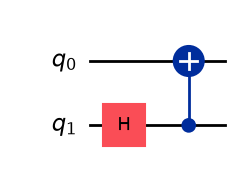

In [40]:
psi0 = QuantumCircuit(2)
psi0.h(1)
psi0.cx(1, 0)

print(Statevector(psi0).data)
psi0.draw('mpl')

$$\ket{\phi ^-} = \frac{1}{\sqrt{2}}(\ket{00} - \ket{11}) $$

[ 0.70710678+0.j  0.        +0.j  0.        +0.j -0.70710678+0.j]


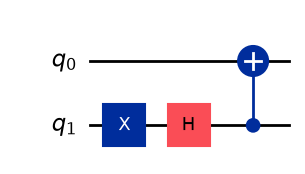

In [39]:
psi1 = QuantumCircuit(2)
psi1.x(1)
psi1.h(1)
psi1.cx(1, 0)

print(Statevector(psi1).data)
psi1.draw('mpl')

$$\ket{\psi ^+} = \frac{1}{\sqrt{2}}(\ket{01} + \ket{10}) $$

[0.        +0.j 0.70710678+0.j 0.70710678+0.j 0.        +0.j]


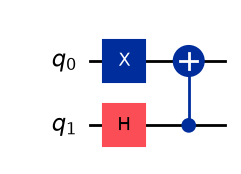

In [38]:
psi2 = QuantumCircuit(2)
psi2.x(0)
psi2.h(1)
psi2.cx(1, 0)

print(Statevector(psi2).data)
psi2.draw('mpl')

$$\ket{\psi ^-} = \frac{1}{\sqrt{2}}(\ket{01} - \ket{10})$$

[ 0.        +0.j  0.70710678+0.j -0.70710678+0.j  0.        +0.j]


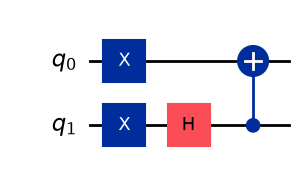

In [37]:
psi3 = QuantumCircuit(2)
psi3.x(1)
psi3.x(0)
psi3.h(1)
psi3.cx(1, 0)

print(Statevector(psi3).data)

psi3.draw('mpl')

### Ejercicio 3

Vamos a tomar el estado $\ket{\phi^+} = \frac{1}{\sqrt{2}}(\ket{00} + \ket{11})$. Si no fueran estados entrelazados, es decir, que la medición de un qubit no condiciona al otro, entonces, se podría escribir como producto (tensorial) de dos qubit independientes. Sean $\ket{\psi_0} = a\ket{0} + b\ket{1}$ y $\ket{\psi_1} = c\ket{0} + d\ket{1}$ donde $a,b,c,d \in \mathbb{C}$.
Supongamos que $\ket{\psi_0\psi_1} = \ket{\phi^+}$ para ver si llegamos a una contradicción.
$$(a\ket{0} + b\ket{1})(c\ket{0} + d\ket{1}) = ac\ket{00} + ad\ket{01} + bc\ket{10} + bd\ket{11}$$

Entonces, $ad = 0$ y $bc = 0$.
- Si $a = 0$ entonces $\ket{\psi_0\psi_1} = bc\ket{10} + bd\ket{11}$ ¡Contradicción.
- Si $b = 0$ entonces $\ket{\psi_0\psi_1} = ac\ket{00} + ad\ket{01}$ ¡Contradicción.
- Si $c = 0$ entonces $\ket{\psi_0\psi_1} = ad\ket{01} + bd\ket{11}$ ¡Contradicción.
- Si $d = 0$ entonces $\ket{\psi_0\psi_1} = ac\ket{00} + bc\ket{10}$ ¡Contradicción.

En todos los casos llegamos a una contradicción, por lo que $\ket{\psi^+}$ no puede ser producto entre los estados de dos qubits. Ídem para los demás casos.

### Ejercicio 4

- $\ket{00} \longrightarrow \ket{\psi^+}$
- $\ket{01} \longrightarrow \ket{\phi^+}$
- $\ket{10} \longrightarrow -\ket{\psi^-}$
- $\ket{11} \longrightarrow -\ket{\phi^-}$

$$
(X \otimes I) \cdot CNOT \cdot (H \otimes I) =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
0 & 0 & 1 & 0\\
0 & 0 & 0 & 1\\
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 1 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 1 & 0\\
0 & 1 & 0 & 1\\
1 & 0 & -1 & 0\\
0 & 1 & 0 & -1
\end{pmatrix} 
= 
\frac{1}{\sqrt{2}}
\begin{pmatrix}
0 & 0 & 0 & 1\\
0 & 0 & 1 & 0\\
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 1 & 0\\
0 & 1 & 0 & 1\\
1 & 0 & -1 & 0\\
0 & 1 & 0 & -1
\end{pmatrix} 
=
\frac{1}{\sqrt{2}}
\begin{pmatrix}
0 & 1 & 0 & -1\\
1 & 0 & -1 & 0\\
1 & 0 & 1 & 0\\
0 & 1 & 0 & 1
\end{pmatrix}
$$

## **Bloque 5: Operador unitario de un circuito**

### Circuito A

$\ket{00} \longrightarrow_1 \frac{1}{\sqrt{2}}(\ket{00} + \ket{10}) \longrightarrow_2 \frac{1}{\sqrt{2}}(\ket{00} + \ket{11}) \longrightarrow_3 \frac{1}{\sqrt{2}}(\ket{10} + \ket{01})$

La matriz resultante es la misma del calculado en el Ejercicio 4 del Bloque anterior:
$$
(X \otimes I) \cdot CNOT \cdot (H \otimes I) = 
\frac{1}{\sqrt{2}}
\begin{pmatrix}
0 & 1 & 0 & -1\\
1 & 0 & -1 & 0\\
1 & 0 & 1 & 0\\
0 & 1 & 0 & 1
\end{pmatrix}
$$

In [41]:
qcA = QuantumCircuit(2)
qcA.h(1)

#Primera linea discontinua
qcA.cx(1, 0)

#Segunda linea discontinua
qcA.x(1)

opA = Operator(qcA)

print(opA.data)

[[ 0.        +0.j  0.70710678+0.j  0.        +0.j -0.70710678+0.j]
 [ 0.70710678+0.j  0.        +0.j -0.70710678+0.j  0.        +0.j]
 [ 0.70710678+0.j  0.        +0.j  0.70710678+0.j  0.        +0.j]
 [ 0.        +0.j  0.70710678+0.j  0.        +0.j  0.70710678+0.j]]


### Circuito B
$\ket{00} \longrightarrow_1 \frac{1}{\sqrt{2}}(\ket{00} + \ket{11}) \longrightarrow_2 \frac{1}{2}(\ket{00} + \ket{01} +\ket{10} - \ket{11}) \longrightarrow_3 \frac{1}{2}(\ket{00} + \ket{01} - \ket{10} + \ket{11})$

$$
(Z \otimes I)\cdot (I \otimes H) \cdot CNOT \cdot (H \otimes I) = 
\frac{1}{2}
\begin{pmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & -1 & 0 \\
0 & 0 & 0 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 1 & 0 & 0 \\
1 & -1 & 0 & 0 \\
0 & 0 & 1 & 1 \\
0 & 0 & 1 & -1
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 1 & 0 \\
0 & 1 & 0 & 1 \\
1 & 0 & -1 & 0 \\
0 & 1 & 0 & -1
\end{pmatrix} =
\frac{1}{2}\begin{pmatrix}
1 & 1 & 1 & 1 \\
1 & -1 & 1 & -1 \\
-1 & -1 & 1 & 1 \\
1 & -1 & -1 & 1
\end{pmatrix}
$$

In [42]:
qcB = QuantumCircuit(2)
qcB.h(1)
qcB.cx(1, 0)

# Primera linea discontinua
qcB.h(0)

# Segunda linea discontinua
qcB.z(1)

opB = Operator(qcB)
print(opB.data)

[[ 0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j]
 [ 0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j]
 [-0.5+0.j -0.5+0.j  0.5+0.j  0.5+0.j]
 [ 0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j]]


### Circuito C

$\ket{00} \longrightarrow_1 \ket{10} \longrightarrow_2 \frac{1}{\sqrt{2}}(\ket{10} + \ket{11}) \longrightarrow_3 \frac{1}{\sqrt{2}}(\ket{00} - \ket{01}) $

$$
(X\otimes Z) \cdot CNOT \cdot (I \otimes H) \cdot (X \otimes I) =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
0 & 0 & 1 & 0 \\
0 & 0 & 0 & -1 \\
1 & 0 & 0 & 0 \\
0 & -1 & 0 & 0
\end{pmatrix}
\begin{pmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0
\end{pmatrix} 
\begin{pmatrix}
1 & 1 & 0 & 0 \\
1 & -1 & 0 & 0 \\
0 & 0 & 1 & 1 \\
0 & 0 & 1 & -1
\end{pmatrix}
\begin{pmatrix}
0 & 0 & 1 & 0 \\
0 & 0 & 0 & 1 \\
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0
\end{pmatrix} =
 \frac{1}{\sqrt{2}}\begin{pmatrix}
1 & -1 & 0 & 0 \\
-1 & -1 & 0 & 0 \\
0 & 0 & 1 & 1 \\
0 & 0 & -1 & 1
\end{pmatrix}
$$

In [43]:
qcC = QuantumCircuit(2)
qcC.x(1)

# Primera linea discontinua
qcC.h(0)
qcC.cx(1, 0)

# Segunda linea discontinua 
qcC.x(1)
qcC.z(0)

opC = Operator(qcC)
print(opC.data)


[[ 0.70710678+0.j -0.70710678+0.j  0.        +0.j  0.        +0.j]
 [-0.70710678+0.j -0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j  0.70710678+0.j]
 [ 0.        +0.j  0.        +0.j -0.70710678+0.j  0.70710678+0.j]]


## **Bloque 6: Circuitos de 3 qubits**

### Ejercicio 1
- Entrada: $\ket{000}$
- Etapa 1: $\ket{100}$
- Etapa 2: $\frac{1}{\sqrt{2}}(\ket{100} + \ket{110})$
- Etapa 3: $\frac{1}{\sqrt{2}}(\ket{110} + \ket{100})$
- Salida: $\frac{1}{\sqrt{2}}(\ket{001} - \ket{011})$


In [52]:
backend = Aer.get_backend('statevector_simulator')

qc = QuantumCircuit(3)

#Etapa 1
qc.x(2)
qc.cx(1, 0)

#Etapa 2
qc.h(1)

#Etapa 3
qc.cx(2, 1)

#Salida 
qc.x(2)
qc.x(0)
qc.z(1)

compiled_circuit = transpile(qc, backend)
result = backend.run(compiled_circuit).result()
svector = result.get_statevector()


for value in svector.data:
    print(value)


0j
(0.7071067811865475-2.7755575615628914e-16j)
0j
(-0.7071067811865477+2.220446049250313e-16j)
0j
0j
0j
0j


### Ejercicio 2

- Entrada: $\ket{000}$
- Puerta H: $\frac{1}{\sqrt{2}}(\ket{000} + \ket{100})$
- Puerta CNOT(0, 1): $\frac{1}{\sqrt{2}}(\ket{000} + \ket{110})$
- Puerta CNOT(1, 2): $\frac{1}{\sqrt{2}}(\ket{000} + \ket{111})$

In [69]:
backend = Aer.get_backend('qasm_simulator')
all_counts = {}

for i in range(8):
    qc = QuantumCircuit(3, 3)

    if i%2 == 1:
        qc.x(0)

    if (i//2)%2 == 1:
        qc.x(1)

    if ((i//2)//2)%2 == 1:
        qc.x(2)

    qc.h(2)
    qc.cx(2, 1)
    qc.cx(1, 0)

    qc.measure([0, 1, 2], [0, 1, 2])


    circuit = transpile(qc, backend)
    job = backend.run(circuit, shots = 4096)
    result = job.result()
    counts = result.get_counts()
    all_counts[i] = counts


In [ ]:
for i, c in all_counts.items():
    print(f'Estado |{i}> : {c}')

Estado |0> : {'111': 1975, '000': 2121}
Estado |1> : {'110': 2053, '001': 2043}
Estado |2> : {'100': 2077, '011': 2019}
Estado |3> : {'101': 2035, '010': 2061}
Estado |4> : {'111': 2069, '000': 2027}
Estado |5> : {'001': 2045, '110': 2051}
Estado |6> : {'011': 2072, '100': 2024}
Estado |7> : {'101': 2108, '010': 1988}


In [72]:
print(all_counts)

{0: {'111': 1975, '000': 2121}, 1: {'110': 2053, '001': 2043}, 2: {'100': 2077, '011': 2019}, 3: {'101': 2035, '010': 2061}, 4: {'111': 2069, '000': 2027}, 5: {'001': 2045, '110': 2051}, 6: {'011': 2072, '100': 2024}, 7: {'101': 2108, '010': 1988}}


In [ ]:
leg = ['State 000', 'State 001', 'State 010','State 011', 'State 100', 'State 101', 'State 110', 'State 111']

fig = plot_histogram([c for c in all_counts.values()], figsize= (10, 5),   legend=leg, sort='asc')
fig.savefig(f'./figures/b6_e2_histograms.png', dpi = 400, bbox_inches = 'tight')

<Figure size 640x480 with 0 Axes>

## **Bloque 7: Cambios de base**

## **Bloque 8: Esfera de Bloch**

## **Bloque 9: Rotaciones y evolución temporal**

## **Bloque 10: Equivalencias de circuitos**

## **Ejercicios opcionales**